# Actuariat-02 — Fréquence × sévérité hiérarchique en C#

**Navigation** · [Sommaire de l’actuariat](README.md) · [Version Python](Actuariat-02-Freq-Sev-Hierarchique.ipynb) · [Prime pure et chargement](Actuariat-01-Prime-Pure-Chargement-CSharp.ipynb) · [Crédibilité de Bühlmann–Straub](Actuariat-03-Actuarial-Credibility.ipynb)

Comment tarifer vingt segments de tailles très inégales ? Vous comparerez des estimations séparées, une prime commune et une mutualisation partielle. Vous examinerez ce que la quantité de données change, y compris quand un modèle prédit bien la prime sans bien identifier un de ses paramètres.

**Prérequis** · Lois de Poisson et normale, modèle génératif, moyenne a posteriori. Exécutez avec **.NET (C#)** et un CPython 3.13 fournissant PyMC 6.0.1, ArviZ 1.1.0 et NumPy 2.4.3. C# porte la simulation et les analyses. PyMC construit et échantillonne le modèle hiérarchique.

In [1]:
#r "nuget: MathNet.Numerics,5.0.0"
#r "nuget: pythonnet,3.1.0"
#load "../../../Config/PythonNetLoader.cs"

#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Security;
using System.Text;
using System.Text.Json;
using MathNet.Numerics.Distributions;
using Microsoft.DotNet.Interactive.Formatting;
using Python.Runtime;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record ActuFigure(string Markup);
Formatter.Register<ActuFigure>((figure, writer) => writer.Write(figure.Markup), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(ActuFigure), "image/svg+xml");

static void RequireActu(bool condition, string explanation)
{
    if (!condition) throw new InvalidOperationException(explanation);
}

// Le quantile linéaire NumPy correspond à une interpolation entre deux statistiques d'ordre.
static double QuantileActu(IEnumerable<double> values, double probability)
{
    var sorted = values.Order().ToArray();
    double index = probability * (sorted.Length - 1);
    int lower = (int)Math.Floor(index);
    int upper = Math.Min(lower + 1, sorted.Length - 1);
    return sorted[lower] + (index - lower) * (sorted[upper] - sorted[lower]);
}

// Le dénominateur n convient aux tirages qui constituent la distribution représentée.
static double StdActu(IReadOnlyCollection<double> values)
{
    double mean = values.Average();
    return Math.Sqrt(values.Sum(value => Math.Pow(value - mean, 2)) / values.Count);
}

// Le petit contrat JSON ne transfère que les paramètres du graphe et les résultats de l'inférence.
static T InferenceActu<T>(string program, object request)
{
    using var gil = Py.GIL();
    using var scope = Py.CreateScope();
    using var data = new PyString(JsonSerializer.Serialize(request));
    scope.Set("request_json", data);
    scope.Exec(program);
    return JsonSerializer.Deserialize<T>(scope.Get<string>("response_json"))
        ?? throw new InvalidOperationException("Le moteur n’a pas renvoyé de posterior.");
}

static string PyVersionActu(string package)
{
    using var gil = Py.GIL();
    using var module = Py.Import(package);
    using var version = module.GetAttr("__version__");
    return version.As<string>();
}

record ActuSeries(string Name, string Color, double[] X, double[] Y, bool Scatter = false);

static void PlotActu(string title, string xLabel, string yLabel, params ActuSeries[] series)
{
    // Les limites suivent les données plutôt que les résultats d'un run de référence.
    const int left = 82, top = 52, width = 660, height = 240;
    double xMin = series.SelectMany(s => s.X).Min(), xMax = series.SelectMany(s => s.X).Max();
    double yMin = series.SelectMany(s => s.Y).Min(), yMax = series.SelectMany(s => s.Y).Max();
    if (xMin == xMax) xMax += 1;
    if (yMin == yMax) yMax += 1;
    static string F(double v) => v.ToString("G5", CultureInfo.InvariantCulture);
    static string E(string v) => SecurityElement.Escape(v)!;
    double X(double v) => left + width * (v - xMin) / (xMax - xMin);
    double Y(double v) => top + height * (yMax - v) / (yMax - yMin);
    var svg = new StringBuilder();
    svg.Append($"<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='{E(title)}' viewBox='0 0 790 410' width='790'><rect width='100%' height='100%' fill='white'/>");
    svg.Append($"<g font-family='system-ui,sans-serif' fill='#172742' font-size='13'><text x='{left}' y='28' font-size='17' font-weight='bold'>{E(title)}</text>");
    for (int tick = 0; tick <= 5; tick++)
    {
        double part = tick / 5.0, zx = left + width * part, zy = top + height * (1 - part);
        svg.Append($"<path d='M{left} {F(zy)}H{left + width}' stroke='#d9e1e8'/><text x='{left - 8}' y='{F(zy + 4)}' text-anchor='end'>{F(yMin + part * (yMax - yMin))}</text>");
        svg.Append($"<text x='{F(zx)}' y='{top + height + 20}' text-anchor='middle'>{F(xMin + part * (xMax - xMin))}</text>");
    }
    svg.Append($"<path d='M{left} {top}V{top + height}H{left + width}' stroke='#526479' fill='none'/><text x='{left + width / 2}' y='340' text-anchor='middle'>{E(xLabel)}</text><text x='22' y='175' transform='rotate(-90 22 175)' text-anchor='middle'>{E(yLabel)}</text>");
    for (int i = 0; i < series.Length; i++)
    {
        var s = series[i];
        // Les séries catégorielles gardent leurs points individuels, même lorsque deux taux se confondent.
        var points = s.X.Zip(s.Y, (x, y) => (X: X(x), Y: Y(y))).ToArray();
        if (!s.Scatter)
        {
            string path = string.Join(" ", points.Select(p => $"{F(p.X)},{F(p.Y)}"));
            svg.Append($"<polyline points='{path}' fill='none' stroke='{s.Color}' stroke-width='2.4'/>");
        }
        else
        {
            foreach (var point in points)
                svg.Append($"<circle cx='{F(point.X)}' cy='{F(point.Y)}' r='3.2' fill='{s.Color}'/>");
        }
        int keyX = left + i % 2 * 320, keyY = 365 + i / 2 * 20;
        svg.Append($"<rect x='{keyX}' y='{keyY - 9}' width='18' height='8' fill='{s.Color}'/><text x='{keyX + 25}' y='{keyY}'>{E(s.Name)}</text>");
    }
    svg.Append("</g></svg>");
    display(new ActuFigure(svg.ToString()));
}

// On libère le GIL après l'amorçage pour que les cellules suivantes puissent le réacquérir.
if (PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "pymc") is not null)
    PythonEngine.BeginAllowThreads();
Console.WriteLine($".NET {Environment.Version} | MathNet 5.0.0 | PyMC {PyVersionActu("pymc")} | ArviZ {PyVersionActu("arviz")}");

Installing Packages MathNet.Numerics pythonnet

.NET 10.0.14 | MathNet 5.0.0 | PyMC 6.0.1 | ArviZ 1.1.0


## 1. Le portefeuille et la vérité générative

La fréquence moyenne vaut $0{,}12$ sinistre par police-année. La fréquence d’un segment est multipliée par un effet lognormal de dispersion $0{,}25$. La moyenne logarithmique des sévérités varie autour de $\log(3\,000)$ avec dispersion $0{,}25$, tandis que l’écart-type individuel commun vaut $0{,}70$.

Sur trois ans, les comptages et sommes de log-coûts constituent les données observées. La somme de $N_k$ log-coûts a pour moyenne $N_km_k$ et pour écart-type $\sigma\sqrt{N_k}$. On connaît la prime générative pour évaluer les méthodes.

In [2]:
int[] insured = [20,150,35,300,25,120,18,250,40,90,22,180,30,100,15,200,28,80,45,60];
const double meanFrequency = .12, frequencySpread = .25, severitySpread = .25, trueSigma = .70;
double meanLogSeverity = Math.Log(3_000);
const int years = 3, seed = 20260825;
var segments = Enumerable.Range(1, insured.Length).Select(k => $"B{k}").ToArray();
int[] exposure = insured.Select(n => n * years).ToArray();

record Observation(int[] Exposure, int[] Count, double[] SumLog, double[] TruePremium);
static Observation Observe(int[] exposure, double[] frequency, double[] logSeverity, double sigma, Random random)
{
    int[] count = exposure.Zip(frequency, (e, rate) => Poisson.Sample(random, e * rate)).ToArray();
    // Une case sans sinistre n'apporte aucune mesure de sévérité. Le masque sera appliqué à l'inférence.
    double[] sumLog = count.Zip(logSeverity, (n, mu) =>
        n == 0 ? 0.0 : Normal.Sample(random, n * mu, sigma * Math.Sqrt(n))).ToArray();
    double[] premium = frequency.Zip(logSeverity, (rate, mu) => rate * Math.Exp(mu + sigma * sigma / 2)).ToArray();
    return new Observation(exposure, count, sumLog, premium);
}

var fresh = new Random(seed);
// Le décalage -s²/2 maintient E[exp(s η - s²/2)] à un.
double[] trueFrequency = insured.Select(_ => meanFrequency * Math.Exp(
    Normal.Sample(fresh, 0, frequencySpread) - frequencySpread * frequencySpread / 2)).ToArray();
double[] trueLogSeverity = insured.Select(_ => Normal.Sample(fresh, meanLogSeverity, severitySpread)).ToArray();
var observed = Observe(exposure, trueFrequency, trueLogSeverity, trueSigma, fresh);
Console.WriteLine($"{insured.Length} segments sur {years} ans, {observed.Count.Sum()} sinistres observés.");
for (int k = 0; k < segments.Length; k++)
    Console.WriteLine($"{segments[k],3} | polices {insured[k],3} | N {observed.Count[k],3} | λ {trueFrequency[k]:F4} | log-sévérité {trueLogSeverity[k]:F3} | π vraie {observed.TruePremium[k],7:F0} €");

20 segments sur 3 ans, 596 sinistres observés.


 B1 | polices  20 | N   5 | λ 0.1213 | log-sévérité 8.364 | π vraie     664 €


 B2 | polices 150 | N  46 | λ 0.0908 | log-sévérité 7.627 | π vraie     238 €


 B3 | polices  35 | N  14 | λ 0.1203 | log-sévérité 7.762 | π vraie     361 €


 B4 | polices 300 | N  87 | λ 0.0866 | log-sévérité 7.802 | π vraie     271 €


 B5 | polices  25 | N   4 | λ 0.0981 | log-sévérité 8.167 | π vraie     441 €


... (11 outputs left out)

B17 | polices  28 | N   7 | λ 0.0872 | log-sévérité 8.036 | π vraie     344 €


B18 | polices  80 | N  24 | λ 0.0962 | log-sévérité 7.855 | π vraie     317 €


B19 | polices  45 | N  18 | λ 0.1284 | log-sévérité 7.879 | π vraie     433 €


B20 | polices  60 | N  20 | λ 0.0906 | log-sévérité 8.674 | π vraie     677 €


## 2. Deux références

Le **no-pooling** donne à chaque segment son propre taux et sa propre moyenne logarithmique. Le **full-pooling** divise le total des sinistres par l’exposition totale et utilise une seule moyenne logarithmique. Ces deux références bénéficient de l’écart-type vrai des sévérités, un avantage que le modèle bayésien ne reçoit pas.

In [3]:
static (double[] Separate, double[] Common) ReferencePremia(Observation sample, double sigma)
{
    double shift = sigma * sigma / 2;
    // La prime séparée est indisponible lorsque le segment ne donne aucune sévérité.
    double[] separate = sample.Exposure.Select((e, k) =>
        sample.Count[k] == 0 ? double.NaN
        : sample.Count[k] / (double)e * Math.Exp(sample.SumLog[k] / sample.Count[k] + shift)).ToArray();
    int total = sample.Count.Sum();
    double common = total / (double)sample.Exposure.Sum() * Math.Exp(sample.SumLog.Sum() / total + shift);
    return (separate, Enumerable.Repeat(common, sample.Count.Length).ToArray());
}

static double RelativeRmse(double[] estimated, double[] truth, IEnumerable<int> positions)
{
    return Math.Sqrt(positions.Average(k => Math.Pow((estimated[k] - truth[k]) / truth[k], 2)));
}
var benchmark = ReferencePremia(observed, trueSigma);
var all = Enumerable.Range(0, insured.Length).ToArray();
var comparable = all.Where(k => double.IsFinite(benchmark.Separate[k])).ToArray();
foreach (int k in all)
    Console.WriteLine($"{segments[k],3} : vraie {observed.TruePremium[k],6:F0} € | séparée {benchmark.Separate[k],6:F0} € | commune {benchmark.Common[k],6:F0} €");
Console.WriteLine($"rRMSE sur {comparable.Length} segments comparables : séparée {RelativeRmse(benchmark.Separate, observed.TruePremium, comparable):F4} | commune {RelativeRmse(benchmark.Common, observed.TruePremium, comparable):F4}.");

 B1 : vraie    664 € | séparée    539 € | commune    414 €


 B2 : vraie    238 € | séparée    291 € | commune    414 €


 B3 : vraie    361 € | séparée    367 € | commune    414 €


 B4 : vraie    271 € | séparée    274 € | commune    414 €


 B5 : vraie    441 € | séparée    190 € | commune    414 €


 B6 : vraie    450 € | séparée    429 € | commune    414 €


... (11 outputs left out)

B18 : vraie    317 € | séparée    322 € | commune    414 €


B19 : vraie    433 € | séparée    399 € | commune    414 €


B20 : vraie    677 € | séparée    790 € | commune    414 €


rRMSE sur 20 segments comparables : séparée 0.2067 | commune 0.3575.


### Lecture des deux références

La prime commune réduit la variance mais gomme les différences réelles. Une prime séparée répond aux différences des segments à condition que chacun fournisse assez d’information. La comparaison principale utilise les mêmes segments lorsque les trois méthodes sont confrontées.

## 3. Modèle non centré

On décrit les taux par $\lambda_k=\exp(\log\lambda_0+\tau_\lambda\eta_k)$ et les log-coûts par $m_k=\mu+\tau u_k$, avec $\eta_k,u_k$ standard normaux. Les trois échelles $\tau_\lambda,\tau,\sigma$ ont des lois demi-normales de paramètre $0{,}5$. Les données observées sont $N_k$ et la somme des log-sévérités sur les segments où $N_k>0$.

Les produits des échelles par les effets latents, l’exponentielle des taux et la variance de sévérité inconnue créent un posterior joint non conjugué. L’échantillonnage NUTS préserve les dépendances utiles au tarif. Les moments marginaux d’une approximation EP ou VMP ne suffisent pas à reconstruire ce résultat joint.

In [4]:
record HierarchyPosterior(double[][] Frequency, double[][] Premium, double[] TauFrequency, double[] TauSeverity,
    double[] Sigma, int Chains, int Draws, int Divergences, string Diagnostics);

const string hierarchyModel = """
    import json, pymc as pm, arviz as az, numpy as np

    request = json.loads(request_json)
    exposure = np.asarray(request["Exposure"])
    counts = np.asarray(request["Count"])
    sum_log = np.asarray(request["SumLog"])
    active = counts > 0
    k = counts.size
    with pm.Model() as model:
        log_lam0 = pm.Normal("log_lam0", np.log(request["PriorFrequency"]), 0.5)
        tau_lam = pm.HalfNormal("tau_lam", 0.5)
        eta_lam = pm.Normal("eta_lam", 0, 1, shape=k)
        lam_k = pm.Deterministic("lam_k", pm.math.exp(log_lam0 + tau_lam * eta_lam))
        mu = pm.Normal("mu", request["PriorMeanLog"], 0.5)
        tau = pm.HalfNormal("tau", 0.5)
        u_k = pm.Normal("u_k", 0, 1, shape=k)
        m_k = mu + tau * u_k
        sigma = pm.HalfNormal("sigma", 0.5)
        pm.Poisson("obs_N", exposure * lam_k, observed=counts)
        pm.Normal("obs_sumlog", counts[active] * m_k[active],
                  sigma * np.sqrt(counts[active]), observed=sum_log[active])
        pm.Deterministic("pi_k", lam_k * pm.math.exp(m_k + sigma**2 / 2))
        trace = pm.sample(request["Draws"], tune=request["Draws"], target_accept=0.9,
                          chains=request["Chains"], cores=1,
                          compute_convergence_checks=False, progressbar=False,
                          random_seed=request["Seed"])
    posterior = trace.posterior
    result = {
        "Frequency": posterior["lam_k"].values.reshape(-1, k).tolist(),
        "Premium": posterior["pi_k"].values.reshape(-1, k).tolist(),
        "TauFrequency": posterior["tau_lam"].values.ravel().tolist(),
        "TauSeverity": posterior["tau"].values.ravel().tolist(),
        "Sigma": posterior["sigma"].values.ravel().tolist(),
        "Chains": posterior.sizes["chain"], "Draws": posterior.sizes["draw"],
        "Divergences": int(trace.sample_stats["diverging"].sum().item()),
        "Diagnostics": az.summary(trace, var_names=["log_lam0", "tau_lam", "mu", "tau", "sigma"]).to_string()
                       if request["Chains"] > 1 else "",
    }
    response_json = json.dumps(result)
    """;

static HierarchyPosterior FitHierarchy(Observation sample, double priorFrequency, double priorMeanLog,
    int draws, int chains, int seed)
{
    // Le masque de sévérité est calculé à partir des mêmes comptages que la vraisemblance Poisson.
    var result = InferenceActu<HierarchyPosterior>(hierarchyModel, new {
        sample.Exposure, sample.Count, sample.SumLog, PriorFrequency = priorFrequency, PriorMeanLog = priorMeanLog,
        Draws = draws, Chains = chains, Seed = seed
    });
    int total = chains * draws;
    int segments = sample.Count.Length;
    RequireActu(result.Chains == chains && result.Draws == draws &&
        result.Frequency.Length == total && result.Premium.Length == total &&
        result.Frequency.All(row => row.Length == segments && row.All(v => v > 0 && double.IsFinite(v))) &&
        result.Premium.All(row => row.Length == segments && row.All(v => v > 0 && double.IsFinite(v))) &&
        result.TauFrequency.Length == total && result.TauSeverity.Length == total && result.Sigma.Length == total,
        "Dimensions ou valeurs du posterior incompatibles.");
    return result;
}

Console.WriteLine("Graphe NUTS : deux hiérarchies non centrées, vraisemblances Poisson et normales conditionnelles, prime jointe.");

Graphe NUTS : deux hiérarchies non centrées, vraisemblances Poisson et normales conditionnelles, prime jointe.


## 4. Échantillonnage et diagnostics

Le modèle principal utilise deux chaînes de 1 500 tirages, chacune après 1 500 pas d’adaptation. La cible d’acceptation de 0,90 affine les pas de NUTS. Les deux chaînes sont exécutées séquentiellement en embarqué.

In [5]:
var posterior = FitHierarchy(observed, meanFrequency, meanLogSeverity, 1_500, 2, seed);
Console.WriteLine($"NUTS : {posterior.Chains} chaînes × {posterior.Draws} tirages, {posterior.Divergences} divergences.");
Console.WriteLine(posterior.Diagnostics);

// La vérité générative est un repère pour sigma, dont le modèle ne voit que des agrégats.
Console.WriteLine($"σ génératif {trueSigma:F2} | médiane {QuantileActu(posterior.Sigma,.5):F2} | Q5 {QuantileActu(posterior.Sigma,.05):F2} | Q95 {QuantileActu(posterior.Sigma,.95):F2}");

NUTS : 2 chaînes × 1500 tirages, 178 divergences.


            mean     sd eti89_lb eti89_ub  ess_bulk  ess_tail r_hat mcse_mean mcse_sd
log_lam0  -2.217  0.049     -2.3     -2.1       639       495  1.00     0.002  0.0014
tau_lam    0.088  0.057    0.012     0.19       736      1136  1.00    0.0021  0.0019
mu         8.006  0.062      7.9      8.1       370       447  1.00    0.0033  0.0024
tau        0.259  0.062     0.16     0.36       330       423  1.00    0.0034  0.0032
sigma       0.42   0.25     0.11     0.87        88        44  1.03     0.022   0.017


σ génératif 0.70 | médiane 0.38 | Q5 0.11 | Q95 0.88


### Lecture des diagnostics

Les agrégats de log-sévérité renseignent directement leurs moyennes. Ils informent moins précisément sur la dispersion individuelle. Dans ce run, σ présente un r-hat de 1,03, un ESS bulk de 88 et un ESS tail de 44. Le Q5–Q95 de 0,11–0,88 englobe la valeur générative de 0,70 tout en signalant une identification faible. Le run principal contient aussi **178 divergences**. Le mélange insuffisant et les divergences signalent une exploration incomplète, avec risque de biais des estimations. L’intervalle et les scores suivants décrivent les tirages obtenus et restent exploratoires. Un bon score de tarif porte sur une combinaison de paramètres. Il ne garantit pas l’identification de chaque paramètre ni le mélange des chaînes dans toutes les directions.

## 5. Primes postérieures et erreur par taille

La prime du segment dépend à la fois de $\lambda_k$, de $m_k$ et de $\sigma$. On calcule ces primes à partir des tirages joints, puis on résume chacune par une moyenne et un écart-type. Le rRMSE met les écarts à l’échelle de la vraie prime de chaque segment.

In [6]:
static double[] PremiumMeans(HierarchyPosterior fit, int dimensions) =>
    Enumerable.Range(0, dimensions).Select(k => fit.Premium.Average(row => row[k])).ToArray();

double[] partial = PremiumMeans(posterior, insured.Length);
// Chaque colonne de la matrice posterior conserve les tirages du même segment.
double[] partialStd = all.Select(k => StdActu(posterior.Premium.Select(row => row[k]).ToArray())).ToArray();
foreach (int k in all)
    Console.WriteLine($"{segments[k],3} | n={insured[k],3} | vraie {observed.TruePremium[k],6:F0} | séparée {benchmark.Separate[k],6:F0} | commune {benchmark.Common[k],6:F0} | partielle {partial[k],6:F0} ± {partialStd[k],6:F0} €");

var methods = new (string Name, double[] Price)[] {
    ("Séparée", benchmark.Separate), ("Commune", benchmark.Common), ("Partielle", partial)
};
var cohorts = new (string Label, int[] Indices)[] {
    ("Observables", comparable),
    ("Petits : n<60", comparable.Where(k => insured[k] < 60).ToArray()),
    ("Grands : n≥150", comparable.Where(k => insured[k] >= 150).ToArray())
};
foreach (var cohort in cohorts)
{
    var scores = methods.Select(m => $"{m.Name}={RelativeRmse(m.Price, observed.TruePremium, cohort.Indices):F4}");
    Console.WriteLine($"rRMSE {cohort.Label} ({cohort.Indices.Length} segments) | {string.Join(" | ", scores)}");
}

 B1 | n= 20 | vraie    664 | séparée    539 | commune    414 | partielle    522 ±    104 €


 B2 | n=150 | vraie    238 | séparée    291 | commune    414 | partielle    282 ±     72 €


 B3 | n= 35 | vraie    361 | séparée    367 | commune    414 | partielle    297 ±     87 €


 B4 | n=300 | vraie    271 | séparée    274 | commune    414 | partielle    270 ±     67 €


 B5 | n= 25 | vraie    441 | séparée    190 | commune    414 | partielle    347 ±     94 €


 B6 | n=120 | vraie    450 | séparée    429 | commune    414 | partielle    373 ±     79 €


... (13 outputs left out)

B20 | n= 60 | vraie    677 | séparée    790 | commune    414 | partielle    626 ±     92 €


rRMSE Observables (20 segments) | Séparée=0.2067 | Commune=0.3575 | Partielle=0.2659


rRMSE Petits : n<60 (10 segments) | Séparée=0.2353 | Commune=0.3576 | Partielle=0.3343


rRMSE Grands : n≥150 (5 segments) | Séparée=0.1384 | Commune=0.4275 | Partielle=0.1367


### Lecture du compromis

Sur ce tirage, l’estimateur séparé, auquel on donne l’écart-type vrai, obtient un rRMSE de 0,2067 sur les vingt segments contre 0,2659 pour le partiel. Chez les grands segments, ils sont presque à égalité (0,1384 et 0,1367). La prime commune est la moins précise sur ce tirage. À l’inverse, la mutualisation partielle peut aider lorsque les observations individuelles sont plus bruitées. Cette comparaison dépend du tirage et du recours à l’écart-type vrai dans les deux références.

## Exercice 1 — Un petit segment attiré vers le collectif

Pour B5, qui porte 25 polices, mesurez l’écart relatif de la prime partielle à la prime séparée. Comparez aussi la prime partielle à la commune. Si vous formez un poids de crédibilité implicite, vérifiez que le dénominateur reste interprétable.

In [7]:
static double? ÉcartRelatifDePrime(double tarifSéparé, double tarifPartiel)
{
    // TODO étudiant : ramener l'écart à une base explicite et conserver son signe.
    return null;
}
int indexB5 = 4;
double? écartB5 = ÉcartRelatifDePrime(benchmark.Separate[indexB5], partial[indexB5]);
if (écartB5 is double écart)
{
    RequireActu(Math.Abs(benchmark.Separate[indexB5] * (1 + écart) - partial[indexB5]) < 1e-8,
        "Vérifiez le sens et le dénominateur de l'écart.");
    Console.WriteLine($"Écart relatif {segments[indexB5]} : {écart:P1}");
}
else
    Console.WriteLine($"À compléter : écart relatif pour {segments[indexB5]}.");

À compléter : écart relatif pour B5.


## 6. De la taille à la précision de la fréquence

On compare la variance a posteriori de $\log\lambda_k$ à l’échelle collective $\bar\tau_\lambda^2$. L’indice $s_k=1-v_k/(v_k+\bar\tau_\lambda^2)$ augmente lorsque cette variance diminue. Il décrit la précision relative de l’estimation, et les petites valeurs correspondent à un effet collectif plus important dans cette lecture. On mesure sa corrélation avec la taille.

In [8]:
// L’indice compare la variance intra-segment à l’échelle entre segments.
double tauSquared = Math.Pow(posterior.TauFrequency.Average(), 2);
double[] posteriorLogVariance = all.Select(k => Math.Pow(
    StdActu(posterior.Frequency.Select(row => Math.Log(row[k])).ToArray()), 2)).ToArray();
double[] precision = posteriorLogVariance.Select(v => 1 - v / (v + tauSquared)).ToArray();
RequireActu(precision.All(s => s >= 0 && s <= 1), "L’indice du lissage sort de [0,1].");
var sizes = insured.Select(n => (double)n).ToArray();
double correlation = MathNet.Numerics.Statistics.Correlation.Pearson(sizes, precision);
foreach (int k in all)
    Console.WriteLine($"{segments[k],3} | n {insured[k],3} | exposition {observed.Exposure[k],4} | sinistres {observed.Count[k],3} | Var(log λ) {posteriorLogVariance[k]:F5} | s {precision[k]:F3}");
Console.WriteLine($"Corrélation de Pearson taille–indice s : {correlation:F3}.");

 B1 | n  20 | exposition   60 | sinistres   5 | Var(log λ) 0.01154 | s 0.404


 B2 | n 150 | exposition  450 | sinistres  46 | Var(log λ) 0.00698 | s 0.528


 B3 | n  35 | exposition  105 | sinistres  14 | Var(log λ) 0.01037 | s 0.430


 B4 | n 300 | exposition  900 | sinistres  87 | Var(log λ) 0.00659 | s 0.543


 B5 | n  25 | exposition   75 | sinistres   4 | Var(log λ) 0.01331 | s 0.370


 B6 | n 120 | exposition  360 | sinistres  41 | Var(log λ) 0.00712 | s 0.524


... (11 outputs left out)

B18 | n  80 | exposition  240 | sinistres  24 | Var(log λ) 0.00857 | s 0.477


B19 | n  45 | exposition  135 | sinistres  18 | Var(log λ) 0.00964 | s 0.448


B20 | n  60 | exposition  180 | sinistres  20 | Var(log λ) 0.00889 | s 0.468


Corrélation de Pearson taille–indice s : 0.843.


## Exercice 2 — Sensibilité au collectif

Réutilisez le modèle avec un a priori centré sur une fréquence collective augmentée de 20 %. Calculez le changement relatif de prime par segment et examinez son rapport à la taille et à l’indice de précision.

In [9]:
#nullable enable
static double[]? MesurerSensibilitéATarif(Observation données, double fréquenceDeRéférence,
    double localisationDeSévérité, double[] primesDeRéférence, int graine)
{
    // TODO étudiant : rappeler FitHierarchy avec la fréquence a priori modifiée, puis mesurer chaque écart.
    return null;
}
double[]? variationDePrime = MesurerSensibilitéATarif(observed, meanFrequency, meanLogSeverity, partial, seed);
if (variationDePrime is not null)
{
    RequireActu(variationDePrime.Length == segments.Length && variationDePrime.All(double.IsFinite),
        "Retournez une variation finie par segment précédent.");
    Console.WriteLine($"Variation moyenne : {variationDePrime.Average():P1}");
}
else
    Console.WriteLine("À compléter : variation relative des primes après ajustement.");

À compléter : variation relative des primes après ajustement.


## 7. Conséquences tarifaires

L’erreur absolue moyenne mesure la taille des écarts et le biais moyen leur direction. Les décomptes par signe distinguent le risque de sous-tarification de celui de perdre des bons risques par surtaxe.

Séparée    | |erreur| 74.4 € | biais -31.4 € | sous 9 | sur 11


Commune    | |erreur| 136.2 € | biais -56.1 € | sous 12 | sur 8


Partielle  | |erreur| 105.4 € | biais -83.4 € | sous 16 | sur 4


Plus forte sous-tarification en euros avec la prime commune : B15, 414 € contre 868 €.


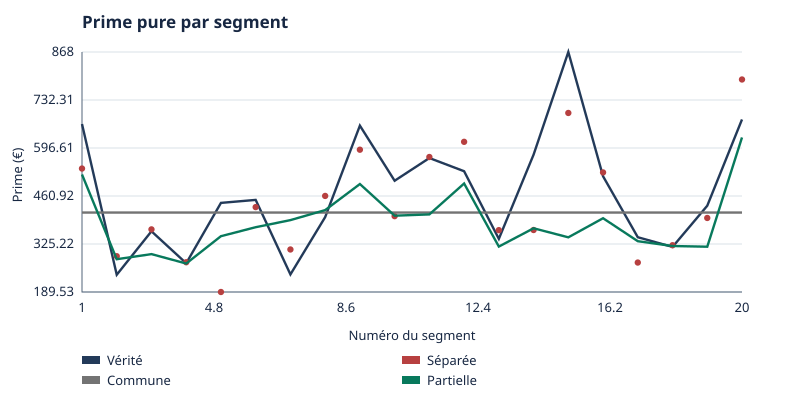

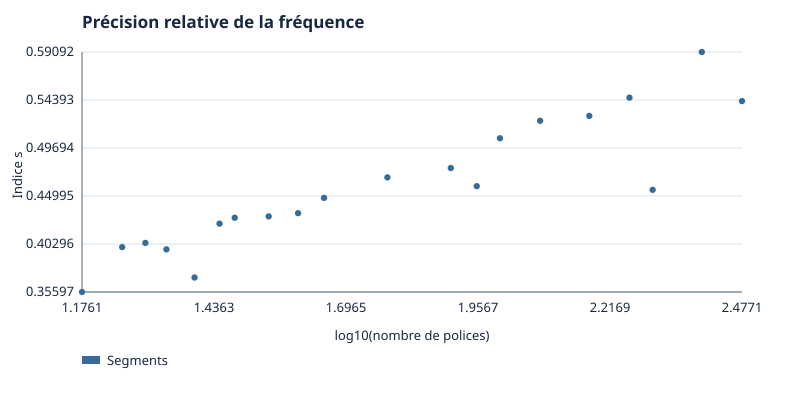

In [10]:
foreach (var m in methods)
{
    // Le masque partagé donne les mêmes dénominateurs.
    double[] errors = comparable.Select(k => m.Price[k] - observed.TruePremium[k]).ToArray();
    int under = errors.Count(e => e < 0), over = errors.Count(e => e > 0);
    Console.WriteLine($"{m.Name,-10} | |erreur| {errors.Average(Math.Abs):F1} € | biais {errors.Average():+0.0;-0.0;0.0} € | sous {under} | sur {over}");
}
int worstCommon = all.MinBy(k => benchmark.Common[k] - observed.TruePremium[k]);
Console.WriteLine($"Plus forte sous-tarification en euros avec la prime commune : {segments[worstCommon]}, {benchmark.Common[worstCommon]:F0} € contre {observed.TruePremium[worstCommon]:F0} €.");

double[] positions = all.Select(k => k + 1.0).ToArray();
PlotActu("Prime pure par segment", "Numéro du segment", "Prime (€)",
    new ActuSeries("Vérité", "#233a59", positions, observed.TruePremium),
    new ActuSeries("Séparée", "#b74040", comparable.Select(k => positions[k]).ToArray(), comparable.Select(k => benchmark.Separate[k]).ToArray(), true),
    new ActuSeries("Commune", "#737373", positions, benchmark.Common),
    new ActuSeries("Partielle", "#08795c", positions, partial));
PlotActu("Précision relative de la fréquence", "log10(nombre de polices)", "Indice s",
    new ActuSeries("Segments", "#356c9c", sizes.Select(n => Math.Log10(n)).ToArray(), precision, true));

### Lecture du prix de l’uniformité

Une prime commune peut bien décrire le portefeuille agrégé et masquer le coût d’un segment. Le segment le plus sous-tarifé en euros peut différer de celui au plus grand écart relatif. Ces deux classements répondent à des questions différentes.

## 8. Trois régimes d’hétérogénéité

On reprend les fréquences génératives et on change l’écart-type des moyennes logarithmiques de sévérité entre segments. Le même aléa contrôle la comparaison des régimes $0{,}05$, $0{,}25$ et $0{,}60$. Ces trois ajustements de 400 tirages sur une chaîne sont des expériences de sensibilité. Ils ne donnent pas de r-hat.

In [11]:
static Observation SensitivityObservation(double spread, int seed, int[] exposure, double[] frequency, double mu, double sigma)
{
    var random = new Random(seed);
    // Le même flux de variations de segment est multiplié par l'écart-type choisi.
    var segmentMean = exposure.Select(_ => Normal.Sample(random, mu, spread)).ToArray();
    return Observe(exposure, frequency, segmentMean, sigma, random);
}

var sensitivity = new Dictionary<double, (double Separate, double Common, double Partial, double Learned)>();
foreach (double spread in new[] { .05, .25, .60 })
{
    var sample = SensitivityObservation(spread, seed, exposure, trueFrequency, meanLogSeverity, trueSigma);
    var baselines = ReferencePremia(sample, trueSigma);
    var fit = FitHierarchy(sample, meanFrequency, meanLogSeverity, 400, 1, seed);
    double[] bayesian = PremiumMeans(fit, insured.Length);
    // Comme dans le carnet Python, la référence séparée omet les segments sans sinistre.
    var active = all.Where(k => double.IsFinite(baselines.Separate[k])).ToArray();
    double separateScore = RelativeRmse(baselines.Separate, sample.TruePremium, active);
    double commonScore = RelativeRmse(baselines.Common, sample.TruePremium, all);
    double partialScore = RelativeRmse(bayesian, sample.TruePremium, all);
    double learned = fit.TauSeverity.Average();
    sensitivity[spread] = (separateScore, commonScore, partialScore, learned);
    Console.WriteLine($"τ réel {spread:F2} | τ appris {learned:F2} | rRMSE séparé {separateScore:F4} ({active.Length} segments) | commun {commonScore:F4} | partiel {partialScore:F4} ({all.Length}) | {fit.Divergences} divergences.");
}

τ réel 0.05 | τ appris 0.16 | rRMSE séparé 0.3163 (20 segments) | commun 0.2529 | partiel 0.1977 (20) | 13 divergences.


τ réel 0.25 | τ appris 0.26 | rRMSE séparé 0.3163 (20 segments) | commun 0.4232 | partiel 0.2251 (20) | 5 divergences.


τ réel 0.60 | τ appris 0.53 | rRMSE séparé 0.3163 (20 segments) | commun 0.7895 | partiel 0.3388 (20) | 28 divergences.


### Lecture des régimes

La dispersion entre segments indique à quel point une moyenne commune peut déformer le prix local. Regardez la dispersion apprise et les trois scores ensemble. Cette expérience conserve le périmètre historique de l’erreur séparée. Elle indique le nombre de segments utilisé pour rendre visibles les éventuels écarts de dénominateur. Les trois ajustements produisent des divergences. Les rRMSE éclairent le comportement du calcul à ce budget sans valider la convergence de la distribution.

## Exercice 3 — Le coût d’une mutualisation aveugle

Identifiez le plus grand écart relatif sous prime commune. Balayez ensuite des valeurs de τ dans l’expérience précédente et trouvez quand le rRMSE commun commence à dépasser le partiel. Utilisez le même générateur et la même graine pour les comparaisons.

In [12]:
static (int Segment, double Seuil)? DiagnostiquerMutualisation(double[] vrai, double[] commun,
    IReadOnlyDictionary<double, (double Separate, double Common, double Partial, double Learned)> résultats)
{
    // TODO étudiant : sélectionner le plus grand écart relatif puis le premier régime admissible de la grille.
    return null;
}
var diagnostic = DiagnostiquerMutualisation(observed.TruePremium, benchmark.Common, sensitivity);
if (diagnostic is { } constat)
{
    RequireActu(constat.Segment >= 0 && constat.Segment < segments.Length &&
        sensitivity.ContainsKey(constat.Seuil), "Retournez un segment et un régime évalués.");
    Console.WriteLine($"{segments[constat.Segment]} | seuil observé τ={constat.Seuil:F2}");
}
else
    Console.WriteLine("À compléter : segment et seuil sur la grille.");

À compléter : segment et seuil sur la grille.


## À retenir

- Les références séparée et commune tirent des conséquences opposées de l’hétérogénéité.
- La mise en commun partielle estime la force du collectif à partir des données.
- Les métriques de tarif et les diagnostics du moteur éclairent des aspects distincts. Vérifiez les deux avant de tirer une conclusion.

## Vérifiez votre compréhension

**Que se passe-t-il si un segment n’a aucun sinistre ?**

<details><summary>Réponse</summary>

Sa vraisemblance de fréquence reste informative. Il ne fournit aucun log-coût et sa sévérité dépend du modèle collectif.

</details>

**Pourquoi adapter la force de la mutualisation ?**

<details><summary>Réponse</summary>

Une grande hétérogénéité signifie qu’une prime commune gomme des différences utiles. Une petite hétérogénéité permet de gagner en précision en combinant les données.

</details>

## Pour aller plus loin

- [Crédibilité de Bühlmann–Straub](Actuariat-03-Actuarial-Credibility.ipynb).
- [Modèles hiérarchiques en Infer.NET](../../../Probas/Infer/Infer-12-Modeles-Hierarchiques.ipynb) et [en PyMC](../../../Probas/PyMC/PyMC-12-Modeles-Hierarchiques.ipynb).
- [Diagnostic des divergences NUTS](https://www.pymc.io/projects/examples/en/latest/diagnostics_and_criticism/Diagnosing_biased_Inference_with_Divergences.html).